# 01 · Preparação dos dados (ETL)

**Fases do CRISP-DM:** 1. Entendimento do negócio · 3. Preparação dos dados

Antes de tirar qualquer conclusão, é preciso **organizar a bagunça**: saber de onde vieram os
dados, o que estava errado neles e o que foi corrigido. Esse trabalho tem um nome técnico,
**ETL**, que são as iniciais de três passos:

1. **Extrair (E):** ler o arquivo original de reservas, sem mexer nele.
2. **Transformar (T):** corrigir o que está errado, traduzir para o português e criar
   informações novas (como o total de noites e a receita de cada reserva).
3. **Carregar (L, de *load*):** salvar a versão limpa num arquivo que todo o grupo usa.

No fim, calculamos os **números do problema do hotel**: quanto se cancela e quanto isso custa.

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "requirements.txt").exists())
sys.path.insert(0, str(RAIZ / "src"))

from etl import SEED, carregar_dados_tratados
from visual import CORES, aplicar_estilo, salvar_figura, salvar_tabela

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

import etl

aplicar_estilo()
pd.set_option("display.max_columns", 40)


def br(numero, casas=0):
    """Formata um número no padrão brasileiro: 119.390 · 37,1."""
    texto = f"{numero:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

## 1. Extração: de onde vêm os dados

Os dados são **reservas reais de dois hotéis em Portugal**: um hotel de cidade (Lisboa) e um
resort (Algarve). Foram publicados por pesquisadores portugueses em 2019 e são de uso livre.
Cada linha do arquivo é **uma reserva**; cada coluna é uma informação sobre ela (quando foi
feita, para quando, quantas pessoas, quanto custa a diária, se foi cancelada...).

O arquivo original fica guardado em `data/raw/hotels.csv` e **nunca é alterado**. Tudo o que
fazemos a seguir trabalha numa cópia.

In [3]:
bruto = etl.extrair()

meses = bruto["arrival_date_month"].map(etl.MESES)
datas = pd.to_datetime(
    {"year": bruto["arrival_date_year"], "month": meses, "day": bruto["arrival_date_day_of_month"]}
)

print(f"Reservas (linhas): {br(len(bruto))}")
print(f"Informações por reserva (colunas): {bruto.shape[1]}")
print(f"Chegadas entre {datas.min():%d/%m/%Y} e {datas.max():%d/%m/%Y}")
print()
print("Reservas por hotel:")
print(bruto["hotel"].value_counts().to_string())

Reservas (linhas): 119.390
Informações por reserva (colunas): 32
Chegadas entre 01/07/2015 e 31/08/2017

Reservas por hotel:
hotel
City Hotel      79330
Resort Hotel    40060


In [4]:
bruto.head(3).T

,0,1,2
hotel,Resort Hotel,Resort Hotel,Resort Hotel
is_canceled,0,0,0
lead_time,342,737,7
arrival_date_year,2015,2015,2015
arrival_date_month,July,July,July
arrival_date_week_number,27,27,27
arrival_date_day_of_month,1,1,1
stays_in_weekend_nights,0,0,0
stays_in_week_nights,0,0,1
adults,2,2,1


## 2. Raio-X da qualidade: o que está errado nos dados

Antes de usar os dados, olhamos linha por linha à procura de problemas. Encontramos cinco
tipos:

- **Informação em branco:** algumas reservas não dizem o número de crianças ou o país.
  Agência e empresa em branco são normais (quer dizer que a reserva não veio por uma).
- **Reservas impossíveis:** reservas com **zero hóspedes** ou com diária **negativa** ou
  absurda (acima de € 1.000 por noite).
- **Linhas repetidas:** muitas reservas são idênticas a outra. Como o arquivo não tem número
  de reserva, não dá para saber se é erro; na maioria são **grupos** que reservaram vários
  quartos iguais de uma vez. Por isso elas **ficam**.
- **Colunas que "entregam a resposta":** quatro colunas só são preenchidas **depois** da
  chegada ou do cancelamento (por exemplo, a situação final da reserva). Usá-las para prever
  cancelamento seria como colar na prova: o resultado ficaria ótimo no papel e inútil na
  vida real.

In [5]:
hospedes = bruto["adults"] + bruto["children"].fillna(0) + bruto["babies"]
problemas = pd.DataFrame(
    [
        ("Número de crianças em branco", "children", bruto["children"].isna().sum(),
         "Preenchido com 0"),
        ("País em branco", "country", bruto["country"].isna().sum(),
         "Preenchido com 'Desconhecido'"),
        ("Agência em branco (normal: reserva sem agência)", "agent", bruto["agent"].isna().sum(),
         "Vira a coluna tem_agente (0/1); o código é descartado"),
        ("Empresa em branco (normal: reserva sem empresa)", "company",
         bruto["company"].isna().sum(),
         "Vira a coluna tem_empresa (0/1); o código é descartado"),
        ("Reserva com zero hóspedes", "adults + children + babies", (hospedes == 0).sum(),
         "Removida (impossível)"),
        ("Diária negativa", "adr", (bruto["adr"] < 0).sum(), "Removida (impossível)"),
        ("Diária acima de € 1.000", "adr", (bruto["adr"] > etl.DIARIA_MAXIMA).sum(),
         "Removida (impossível)"),
        ("Linha idêntica a outra", "todas", bruto.duplicated().sum(),
         "Mantida (em geral são reservas de grupo reais)"),
        ("Coluna só conhecida depois da chegada ou do cancelamento",
         ", ".join(etl.COLUNAS_DESCARTADAS), len(bruto),
         "Coluna descartada (seria 'colar na prova')"),
    ],
    columns=["problema", "colunas", "linhas_afetadas", "o_que_fizemos"],
)
problemas["percentual_das_linhas"] = (100 * problemas["linhas_afetadas"] / len(bruto)).round(3)
salvar_tabela(problemas, "01_problemas_de_qualidade")
problemas

,problema,colunas,linhas_afetadas,o_que_fizemos,percentual_das_linhas
0,Número de crianças em branco,children,4,Preenchido com 0,0.003
1,País em branco,country,488,Preenchido com 'Desconhecido',0.409
2,Agência em branco (normal: reserva sem agência),agent,16340,Vira a coluna tem_agente (0/1); o código é des...,13.686
3,Empresa em branco (normal: reserva sem empresa),company,112593,Vira a coluna tem_empresa (0/1); o código é de...,94.307
4,Reserva com zero hóspedes,adults + children + babies,180,Removida (impossível),0.151
5,Diária negativa,adr,1,Removida (impossível),0.001
6,Diária acima de € 1.000,adr,1,Removida (impossível),0.001
7,Linha idêntica a outra,todas,31994,Mantida (em geral são reservas de grupo reais),26.798
8,Coluna só conhecida depois da chegada ou do ca...,"reservation_status, reservation_status_date, a...",119390,Coluna descartada (seria 'colar na prova'),100.000


In [6]:
print(f"Menor diária: € {br(bruto['adr'].min(), 2)}")
print(f"Maior diária: € {br(bruto['adr'].max(), 2)}")
print(f"Diária média típica (mediana): € {br(bruto['adr'].median(), 2)}")

Menor diária: € -6,38
Maior diária: € 5.400,00
Diária média típica (mediana): € 94,58


**Em resumo:** os problemas graves (reservas impossíveis) atingem **menos de 2 em cada 1.000
reservas**. Os demais se resolvem com regras simples, sem jogar informação fora.

## 3. Transformação: o que corrigimos

As regras abaixo foram combinadas com o grupo antes do trabalho começar (issue #1):

1. **Remover só o que é impossível:** zero hóspedes, diária negativa e diária acima de
   € 1.000. Nada mais é removido.
2. **Descartar as colunas que "entregam a resposta"** e os códigos de agência e de empresa
   (o código em si não diz nada ao gerente; guardamos só "veio ou não por agência/empresa").
3. **Traduzir** todos os nomes de colunas e categorias para o português
   (ex.: `Online TA` → `Agência online`, `Non Refund` → `Não reembolsável`).
4. **Criar informações novas:** data de chegada, total de noites, total de hóspedes,
   **receita estimada** (diária × noites) e a separação entre **treino** e **teste**.

Primeiro, quantas reservas sai em cada regra de remoção, uma depois da outra:

In [7]:
etapas = []
atual = bruto.copy()
etapas.append(("Arquivo original", len(atual)))

h = atual["adults"] + atual["children"].fillna(0) + atual["babies"]
atual = atual[h > 0]
etapas.append(("Sem reservas com zero hóspedes", len(atual)))

atual = atual[atual["adr"] >= 0]
etapas.append(("Sem diária negativa", len(atual)))

atual = atual[atual["adr"] <= etl.DIARIA_MAXIMA]
etapas.append(("Sem diária acima de € 1.000", len(atual)))

funil = pd.DataFrame(etapas, columns=["etapa", "reservas"])
funil["removidas_nesta_etapa"] = (-funil["reservas"].diff()).fillna(0).astype(int)
funil

,etapa,reservas,removidas_nesta_etapa
0,Arquivo original,119390,0
1,Sem reservas com zero hóspedes,119210,180
2,Sem diária negativa,119209,1
3,Sem diária acima de € 1.000,119208,1


Agora aplicamos **todas as regras de uma vez** com a função oficial do projeto
(`transformar`, em `src/etl.py`), que é a mesma que gera o arquivo usado pelo grupo:

In [8]:
tratado = etl.transformar(bruto)

print(f"Antes: {br(len(bruto))} reservas e {bruto.shape[1]} colunas")
print(f"Depois: {br(len(tratado))} reservas e {tratado.shape[1]} colunas")
print(f"Removidas: {br(len(bruto) - len(tratado))} reservas "
      f"({br(100 * (len(bruto) - len(tratado)) / len(bruto), 2)}% do total)")

Antes: 119.390 reservas e 32 colunas
Depois: 119.208 reservas e 32 colunas
Removidas: 182 reservas (0,15% do total)


In [9]:
tratado.head(3).T

,0,1,2
hotel,Resort,Resort,Resort
cancelada,0,0,0
antecedencia_dias,342,737,7
data_chegada,2015-07-01 00:00:00,2015-07-01 00:00:00,2015-07-01 00:00:00
ano_chegada,2015,2015,2015
mes_chegada,7,7,7
semana_chegada,27,27,27
noites_fim_semana,0,0,0
noites_semana,0,0,1
total_noites,0,0,1


Exemplo de tradução: por onde as reservas chegam (antes e depois).

In [10]:
traducao = pd.DataFrame(
    etl.TRADUCOES["market_segment"].items(), columns=["original (inglês)", "traduzido"]
)
traducao["reservas no original"] = traducao["original (inglês)"].map(
    bruto["market_segment"].value_counts()
)
traducao["reservas na base tratada"] = traducao["traduzido"].map(
    tratado["segmento_mercado"].value_counts()
)
traducao.sort_values("reservas no original", ascending=False)

,original (inglês),traduzido,reservas no original,reservas na base tratada
0,Online TA,Agência online,56477,56408
1,Offline TA/TO,Agência/operadora tradicional,24219,24181
2,Groups,Grupos,19811,19790
3,Direct,Direto,12606,12582
4,Corporate,Corporativo,5295,5282
5,Complementary,Cortesia,743,728
6,Aviation,Aviação,237,235
7,Undefined,Indefinido,2,2


A separação entre **treino** e **teste** segue a vida real: o modelo de previsão vai
**aprender** com as reservas que chegaram até o fim de 2016 e ser **testado** nas reservas de
2017, que ele nunca viu. É como estudar com as provas dos anos anteriores e fazer a prova
deste ano.

In [11]:
resumo_conjunto = (
    tratado.groupby("conjunto", observed=True)
    .agg(
        reservas=("cancelada", "size"),
        primeira_chegada=("data_chegada", "min"),
        ultima_chegada=("data_chegada", "max"),
        taxa_cancelamento_pct=("cancelada", "mean"),
    )
    .reindex(["treino", "teste"])
)
resumo_conjunto["taxa_cancelamento_pct"] = (100 * resumo_conjunto["taxa_cancelamento_pct"]).round(1)
resumo_conjunto

,reservas,primeira_chegada,ultima_chegada,taxa_cancelamento_pct
conjunto,,,,
treino,78589,2015-07-01,2016-12-31,36.2
teste,40619,2017-01-01,2017-08-31,38.7


## 4. Carga: salvar a base limpa e conferir

A base tratada é salva em `data/processed/reservas_tratadas.parquet` (um formato que guarda
os dados compactados e já com o tipo certo de cada coluna). Depois, o próprio notebook
**confere sozinho** se está tudo certo: se algo estiver errado, ele para com erro.

In [12]:
caminho = etl.carregar(tratado)
base = carregar_dados_tratados()

assert len(base) == len(bruto) - 182 == 119_208, "Número de reservas diferente do esperado"
assert list(base.columns) == etl.COLUNAS_TRATADAS, "Colunas diferentes das combinadas"
assert base.isna().sum().sum() == 0, "Ainda há valores em branco"
assert (base["total_hospedes"] > 0).all(), "Há reserva sem hóspede"
assert base["diaria_media"].between(0, etl.DIARIA_MAXIMA).all(), "Há diária impossível"
assert not set(etl.COLUNAS_DESCARTADAS) & set(base.columns), "Coluna proibida na base"
assert set(base["cancelada"].unique()) == {0, 1}, "Alvo fora do padrão 0/1"
assert base["mes_chegada"].between(1, 12).all(), "Mês fora de 1 a 12"
assert (base["conjunto"] == "treino").sum() == 78_589, "Tamanho do treino diferente"
assert (base["conjunto"] == "teste").sum() == 40_619, "Tamanho do teste diferente"
assert (base.loc[base["conjunto"] == "teste", "ano_chegada"] == 2017).all()
assert (base.loc[base["conjunto"] == "treino", "data_chegada"] <= "2016-12-31").all()
pd.testing.assert_frame_equal(base, tratado)

print(f"Base salva em data/processed/{caminho.name}")
print("Todas as conferências passaram.")

Base salva em data/processed/reservas_tratadas.parquet
Todas as conferências passaram.


In [13]:
pd.DataFrame({"coluna": base.columns, "tipo": base.dtypes.astype(str).values})

,coluna,tipo
0,hotel,category
1,cancelada,int64
2,antecedencia_dias,int64
3,data_chegada,datetime64[us]
4,ano_chegada,int64
5,mes_chegada,int64
6,semana_chegada,int64
7,noites_fim_semana,int64
8,noites_semana,int64
9,total_noites,int64


## 5. Os números do problema do hotel

Com a base limpa, medimos o tamanho do problema. A **receita estimada** de cada reserva é a
diária média multiplicada pelo número de noites. Para as reservas canceladas, é a receita que
o hotel **esperava receber e não recebeu** (uma estimativa: parte desses quartos pode ter
sido revendida).

In [14]:
canceladas = base[base["cancelada"] == 1]
por_hotel = base.groupby("hotel", observed=True)
receita_total = base["receita_estimada"].sum()
receita_cancelada = canceladas["receita_estimada"].sum()
treino = base[base["conjunto"] == "treino"]
teste = base[base["conjunto"] == "teste"]

linhas = [
    ("Reservas na base tratada", "Todos", len(base), "reservas"),
    ("Reservas canceladas", "Todos", len(canceladas), "reservas"),
    ("Taxa de cancelamento", "Todos", 100 * base["cancelada"].mean(), "%"),
    ("Receita estimada de todas as reservas", "Todos", receita_total, "€"),
    ("Receita estimada das reservas canceladas", "Todos", receita_cancelada, "€"),
    ("Parte da receita estimada que foi cancelada", "Todos",
     100 * receita_cancelada / receita_total, "%"),
]
for hotel, grupo in por_hotel:
    canc = grupo[grupo["cancelada"] == 1]
    linhas += [
        ("Reservas na base tratada", hotel, len(grupo), "reservas"),
        ("Reservas canceladas", hotel, len(canc), "reservas"),
        ("Taxa de cancelamento", hotel, 100 * grupo["cancelada"].mean(), "%"),
        ("Receita estimada das reservas canceladas", hotel, canc["receita_estimada"].sum(), "€"),
    ]
linhas += [
    ("Reservas no treino (chegadas até 31/12/2016)", "Todos", len(treino), "reservas"),
    ("Taxa de cancelamento no treino", "Todos", 100 * treino["cancelada"].mean(), "%"),
    ("Reservas no teste (chegadas em 2017)", "Todos", len(teste), "reservas"),
    ("Taxa de cancelamento no teste", "Todos", 100 * teste["cancelada"].mean(), "%"),
]

resumo = pd.DataFrame(linhas, columns=["indicador", "hotel", "valor", "unidade"])
resumo["valor"] = resumo["valor"].astype(float).round(2)
salvar_tabela(resumo, "01_resumo_do_problema")
resumo

,indicador,hotel,valor,unidade
0,Reservas na base tratada,Todos,119208.00,reservas
1,Reservas canceladas,Todos,44198.00,reservas
2,Taxa de cancelamento,Todos,37.08,%
3,Receita estimada de todas as reservas,Todos,42708813.15,€
4,Receita estimada das reservas canceladas,Todos,16721837.12,€
5,Parte da receita estimada que foi cancelada,Todos,39.15,%
6,Reservas na base tratada,Hotel de cidade,79162.00,reservas
7,Reservas canceladas,Hotel de cidade,33078.00,reservas
8,Taxa de cancelamento,Hotel de cidade,41.79,%
9,Receita estimada das reservas canceladas,Hotel de cidade,10879659.78,€


In [15]:
taxa = 100 * base["cancelada"].mean()
print(f"Cancelamento geral: {br(taxa, 1)}% (cerca de {round(taxa / 10)} em cada 10 reservas)")
for hotel, grupo in por_hotel:
    t = 100 * grupo["cancelada"].mean()
    print(f"  {hotel}: {br(t, 1)}%")
print(f"Receita estimada das canceladas: € {br(receita_cancelada / 1e6, 1)} milhões "
      f"de € {br(receita_total / 1e6, 1)} milhões ({br(100 * receita_cancelada / receita_total, 0)}%)")

Cancelamento geral: 37,1% (cerca de 4 em cada 10 reservas)
  Hotel de cidade: 41,8%
  Resort: 27,8%
Receita estimada das canceladas: € 16,7 milhões de € 42,7 milhões (39%)


## 6. Gráficos para a apresentação

Dois gráficos, um para cada mensagem:

1. **A limpeza foi pequena e segura:** quase nada precisou ser removido.
2. **O problema é maior no hotel de cidade:** lá, mais de 4 em cada 10 reservas são canceladas.

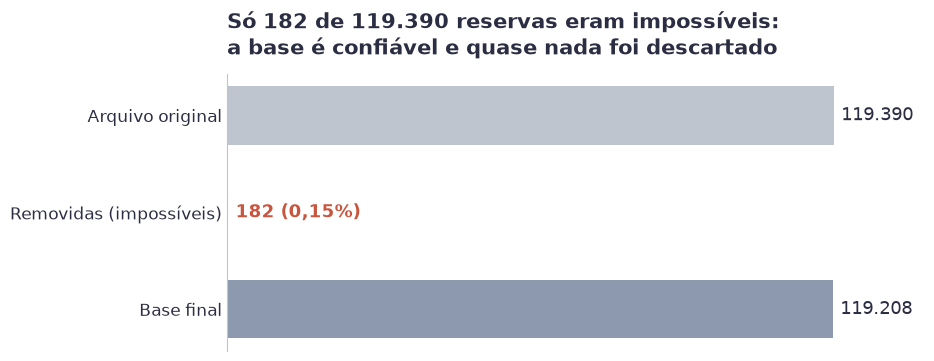

In [16]:
removidas = len(bruto) - len(base)
fig, ax = plt.subplots(figsize=(9, 3.6))
rotulos = ["Arquivo original", "Removidas (impossíveis)", "Base final"]
valores = [len(bruto), removidas, len(base)]
cores = [CORES["neutro"], CORES["destaque"], CORES["veio"]]
ax.barh(rotulos[::-1], valores[::-1], color=cores[::-1], height=0.6)
for i, v in enumerate(valores[::-1]):
    destaque = v == removidas
    texto = f"{br(v)} ({br(100 * v / len(bruto), 2)}%)" if destaque else br(v)
    ax.text(v + 1500, i, texto, va="center", fontsize=13,
            color=CORES["destaque"] if destaque else CORES["texto"],
            fontweight="bold" if destaque else "normal")
ax.set_xlim(0, len(bruto) * 1.15)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title(
    f"Só {removidas} de {br(len(bruto))} reservas eram impossíveis:\n"
    "a base é confiável e quase nada foi descartado"
)
salvar_figura(fig, "01_funil_da_limpeza")
plt.show()

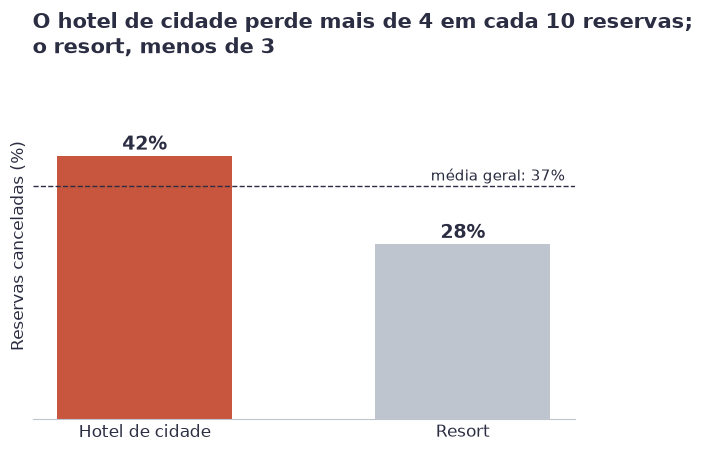

In [17]:
taxas = (100 * por_hotel["cancelada"].mean()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
cores = [CORES["destaque"] if h == taxas.idxmax() else CORES["neutro"] for h in taxas.index]
barras = ax.bar(taxas.index.astype(str), taxas.values, color=cores, width=0.55)
for barra, v in zip(barras, taxas.values):
    ax.text(barra.get_x() + barra.get_width() / 2, v + 1, f"{br(v, 0)}%",
            ha="center", fontsize=14, fontweight="bold", color=CORES["texto"])
ax.axhline(taxa, color=CORES["texto"], linestyle="--", linewidth=1)
ax.text(1.32, taxa + 0.8, f"média geral: {br(taxa, 0)}%", ha="right", fontsize=11,
        color=CORES["texto"])
ax.set_ylim(0, 55)
ax.set_ylabel("Reservas canceladas (%)")
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.set_title("O hotel de cidade perde mais de 4 em cada 10 reservas;\no resort, menos de 3")
salvar_figura(fig, "01_cancelamento_por_hotel")
plt.show()

## 7. Conclusão

- Os dados são **confiáveis**: das 119.390 reservas originais, só **182** eram impossíveis
  (zero hóspedes ou diária absurda) e foram removidas. Ficaram **119.208** reservas.
- Corrigimos os espaços em branco, traduzimos tudo para o português e **tiramos as
  informações que só existem depois da chegada**, para que a previsão seja honesta.
- O problema é grande: **37% das reservas são canceladas** (quase 4 em cada 10), o que soma
  cerca de **€ 16,7 milhões** de receita estimada que não se concretizou, **39%** de toda a
  receita reservada.
- O **hotel de cidade** sofre mais: **42%** de cancelamento, contra **28%** no resort.
- A base está pronta e separada em **treino** (78.589 reservas, até 2016) e **teste**
  (40.619 reservas, 2017) para as próximas etapas: entender quem cancela e prever o risco.